# FlashEats: Class 7 Challenge
## Model the Business Workflow with Data

### Client question
> **“Show us where in the workflow delay accumulates, how customers react, what interventions we make, and which metrics we should use to improve the project KPI.”**

Do not repeat source discovery, retrieval, or data-cleaning work. Today the goal is to build a useful business-workflow model.

In [1]:
import json, sqlite3, zipfile
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns",100)
pd.set_option("display.max_colwidth",140)

def find_pack_root(search_root=Path("/content")):
    for candidate in search_root.rglob("FlashEats_Classroom_Pack_V2"):
        if (candidate/"database"/"flasheats.db").exists(): return candidate
    return None

# Local run: the notebook usually already lives inside the pack root.
BASE = None
if (Path.cwd() / "database" / "flasheats.db").exists():
    BASE = Path.cwd()
elif Path.cwd().name == "FlashEats_Classroom_Pack_V2":
    BASE = Path.cwd()

if BASE is None:
    BASE=find_pack_root()
if BASE is None:
    try:
        from google.colab import files
        print("Upload the FlashEats Class 7 classroom pack ZIP.")
        uploaded=files.upload(); zip_name=next(n for n in uploaded if n.endswith(".zip"))
        extract_dir=Path("/content/flasheats_class7"); extract_dir.mkdir(parents=True,exist_ok=True)
        with zipfile.ZipFile(zip_name) as z: z.extractall(extract_dir)
        BASE=find_pack_root(Path("/content"))
    except Exception as e: print(e)
if BASE is None:
    BASE=find_pack_root(Path.cwd())
if BASE is None: raise FileNotFoundError("Could not locate FlashEats_Classroom_Pack_V2")
print("Using pack:",BASE)

Using pack: /home/utkuputku/Desktop/flasheats-classroom-pack


In [2]:
con=sqlite3.connect(BASE/"database"/"flasheats.db")
orders=pd.read_sql("SELECT * FROM orders",con)
customers=pd.read_sql("SELECT * FROM customers",con)
restaurants=pd.read_sql("SELECT * FROM restaurants",con)
drivers=pd.read_sql("SELECT * FROM drivers",con)
tickets=pd.read_csv(BASE/"data"/"support_tickets.csv")
customer_actions=pd.read_csv(BASE/"data"/"customer_app_actions.csv")
interventions=pd.read_csv(BASE/"data"/"order_interventions.csv")
outcomes=pd.read_csv(BASE/"data"/"order_outcomes.csv")
with open(BASE/"data"/"class7_model_brief.json") as f: model_brief=json.load(f)
print("orders",orders.shape,"actions",customer_actions.shape,"interventions",interventions.shape,"outcomes",outcomes.shape)
print("Project KPI:",model_brief["project_kpi"])

orders (1603, 13) actions (2365, 6) interventions (430, 6) outcomes (1600, 6)
Project KPI: Reduce late delivery rate


In [3]:
# a few extra sources the model needs: dispatch (reassignments + planned pickup), driver app, restaurant status
import numpy as np
import matplotlib.pyplot as plt

dispatch = pd.DataFrame(json.loads((BASE / "api" / "dispatch_data.json").read_text()))
with open(BASE / "data" / "driver_events.json") as f:
    driver_events = pd.DataFrame([{"driver_id": d["driver_id"], **e} for d in json.load(f) for e in d["events"]])
restaurant_status = pd.read_csv(BASE / "data" / "restaurant_status.csv").drop_duplicates()
order_events = pd.read_csv(BASE / "data" / "order_events.csv")
customer_interactions = pd.read_csv(BASE / "data" / "customer_interactions.csv")

ts = lambda s: pd.to_datetime(s, format="mixed", errors="coerce")
base_orders = orders.drop_duplicates("order_id", keep="first").copy()
for c in ["created_at", "promised_eta", "pickup_at", "actual_delivery_at"]:
    base_orders[c] = ts(base_orders[c])
for c in ["assigned_at", "reassigned_at", "estimated_pickup_at", "current_delivery_eta"]:
    dispatch[c] = ts(dispatch[c])
driver_events["timestamp"] = ts(driver_events["timestamp"])
customer_actions["action_at"] = ts(customer_actions["action_at"])
interventions["intervention_at"] = ts(interventions["intervention_at"])
tickets_clean = tickets.drop_duplicates().copy()
tickets_clean["created_at"] = ts(tickets_clean["created_at"])
restaurant_status["last_updated_at"] = ts(restaurant_status["last_updated_at"])
print("dispatch", dispatch.shape, "| driver events", driver_events.shape)

dispatch (1600, 9) | driver events (10035, 6)


# Challenge 1: Reconstruct the order lifecycle

Choose 3 orders:
- one delivered on time,
- one delivered late,
- one with an intervention.

Build a timeline with:

`event_time | event_type | actor | source_system`

Include as many lifecycle events as the data supports.

### Hint
Start from one `order_id`, collect events from each source, then sort by time.

In [4]:
base_orders=orders.drop_duplicates("order_id",keep="first")
late_order=outcomes[outcomes.late_flag==1].order_id.iloc[0]
on_time_order=outcomes[outcomes.late_flag==0].order_id.iloc[0]
intervention_order=interventions.order_id.iloc[0]
print("late",late_order,"on-time",on_time_order,"intervention",intervention_order)

base_orders = base_orders.copy()
for c in ["created_at", "promised_eta", "pickup_at", "actual_delivery_at"]:
    base_orders[c] = ts(base_orders[c])

def build_order_timeline(order_id):
    rows = []
    add = lambda t, e, a, s: rows.append({"event_time": t, "event_type": e, "actor": a, "source_system": s}) if pd.notna(t) else None

    o = base_orders.loc[base_orders.order_id == order_id].iloc[0]
    add(o.created_at, "order_created", f"customer {o.customer_id}", "orders db")
    add(o.promised_eta, "promised_eta (the promise)", "system", "orders db")
    add(o.actual_delivery_at, "delivered (db)", "driver", "orders db")

    d = dispatch.loc[dispatch.order_id == order_id].iloc[0]
    add(d.assigned_at, "driver_assigned", f"driver {d.original_driver_id}", "dispatch")
    add(d.reassigned_at, "driver_reassigned", f"driver {d.driver_id}", "dispatch")
    add(d.estimated_pickup_at, "planned_pickup (eta assumption)", "system", "dispatch")

    for _, e in driver_events[(driver_events.order_id == order_id) & (driver_events.type != "gps_ping")].iterrows():
        add(e.timestamp, f"{e.type} (driver app)", f"driver {e.driver_id}", "driver app")
    for _, r in restaurant_status[restaurant_status.order_id == order_id].iterrows():
        add(r.last_updated_at, f"restaurant_status={r.status.strip().lower()}", f"restaurant {r.restaurant_id}", "restaurant_status")
    for _, a in customer_actions[customer_actions.order_id == order_id].iterrows():
        add(a.action_at, a.action_type.lower(), f"customer {a.customer_id}", a.channel)
    for _, t in tickets_clean[tickets_clean.order_id == order_id].iterrows():
        add(t.created_at, f"support_ticket: {t.category.strip()}", "customer", "support")
    for _, i in interventions[interventions.order_id == order_id].iterrows():
        add(i.intervention_at, f"intervention: {i.intervention_type} ({i.reason})", i.initiated_by, "interventions")

    tl = pd.DataFrame(rows).sort_values("event_time").reset_index(drop=True)
    tl["min_from_order"] = ((tl.event_time - o.created_at).dt.total_seconds() / 60).round(1)
    return tl

for label, oid in [("ON TIME", on_time_order), ("LATE", late_order), ("INTERVENTION", intervention_order)]:
    oc = outcomes.set_index("order_id").loc[oid]
    print(f"\n{label}: {oid} -> {oc.outcome_bucket}, delay {oc.delay_min} min")
    display(build_order_timeline(oid))

late O00001 on-time O00003 intervention O00781

ON TIME: O00003 -> delivered_on_time, delay -4.41 min


,event_time,event_type,actor,source_system,min_from_order
0,2026-08-01 19:35:00.000000,order_created,customer C0855,orders db,0.0
1,2026-08-01 19:35:00.002443,driver_assigned,driver D039,dispatch,0.0
2,2026-08-01 19:35:00.002443,assigned (driver app),driver D039,driver app,0.0
3,2026-08-01 19:48:00.000000,restaurant_status=preparing,restaurant R010,restaurant_status,13.0
4,2026-08-01 19:53:00.000000,planned_pickup (eta assumption),system,dispatch,18.0
5,2026-08-01 19:57:50.820366,picked_up (driver app),driver D039,driver app,22.8
6,2026-08-01 20:13:28.061191,delivered (db),driver,orders db,38.5
7,2026-08-01 20:13:28.061191,delivered (driver app),driver D039,driver app,38.5
8,2026-08-01 20:17:52.941967,promised_eta (the promise),system,orders db,42.9



LATE: O00001 -> delivered_late, delay 10.82 min


,event_time,event_type,actor,source_system,min_from_order
0,2026-08-13 12:56:00.000000,order_created,customer C0168,orders db,0.0
1,2026-08-13 13:01:09.659644,driver_assigned,driver D103,dispatch,5.2
2,2026-08-13 13:01:09.659644,assigned (driver app),driver D103,driver app,5.2
3,2026-08-13 13:08:00.000000,intervention: DRIVER_REASSIGNMENT (driver_unavailable),dispatch,interventions,12.0
4,2026-08-13 13:14:00.000000,planned_pickup (eta assumption),system,dispatch,18.0
5,2026-08-13 13:21:00.000000,eta_viewed,customer C0168,mobile_app,25.0
6,2026-08-13 13:35:49.825561,picked_up (driver app),driver D103,driver app,39.8
7,2026-08-13 14:11:36.000000,promised_eta (the promise),system,orders db,75.6
8,2026-08-13 14:20:36.000000,support_opened,customer C0168,mobile_app,84.6
9,2026-08-13 14:22:25.035899,delivered (db),driver,orders db,86.4



INTERVENTION: O00781 -> delivered_late, delay 13.07 min


,event_time,event_type,actor,source_system,min_from_order
0,2026-08-22 12:33:00.000000,order_created,customer C0103,orders db,0.0
1,2026-08-22 12:40:42.931820,driver_assigned,driver D103,dispatch,7.7
2,2026-08-22 12:40:42.931820,assigned (driver app),driver D103,driver app,7.7
3,2026-08-22 12:51:00.000000,planned_pickup (eta assumption),system,dispatch,18.0
4,2026-08-22 12:54:00.000000,eta_viewed,customer C0103,mobile_app,21.0
5,2026-08-22 12:57:00.000000,intervention: PRIORITY_DISPATCH (late_risk),operations,interventions,24.0
6,2026-08-22 13:04:00.000000,restaurant_status=ready,restaurant R019,restaurant_status,31.0
7,2026-08-22 13:11:17.309762,picked_up (driver app),driver D103,driver app,38.3
8,2026-08-22 13:48:36.000000,promised_eta (the promise),system,orders db,75.6
9,2026-08-22 14:01:40.289785,delivered (db),driver,orders db,88.7


What the three timelines show:
- The same shape shows up every time. Order created, driver assigned within a few minutes, dispatch plans the pickup at exactly +18 min, and the real pickup lands later than that. Once pickup slips, the ride leg has to make the time back.
- On time (O00003): picked up ~5 min after the planned pickup, ride beat its plan, delivered 4 min early.
- Late (O00001): picked up ~40 min after ordering, 22 min behind the plan. The ride actually beat its plan by ~11 min, but that couldn't cover a 22 min pickup slip, so it lands 11 min late. The customer checked the ETA, then opened support ~9 min after the promise passed. Also weird: there's a DRIVER_REASSIGNMENT intervention at +12 min, but dispatch and the driver app show the same driver the whole time. More on that below.
- Intervention (O00781): priority dispatch at +24 min, 6 min after the planned pickup, so ops did notice it was slipping. Pickup still took until +38 min and it ended up 13 min late.
- What's missing is what matters most: nothing says when the driver reached the restaurant or when the food was actually ready. That gap in the timeline is exactly where the delay piles up.

# Challenge 2: Define the canonical project model

Your model must support:
1. customer → orders
2. order → customer interactions
3. order → support interactions
4. order → interventions
5. order → outcome

For each table, document:
- primary key,
- important foreign keys,
- grain.

Then explain why this model is better for the project than mirroring every source-system table.

In [5]:
sources={"orders":orders,"customer_actions":customer_actions,"support_tickets":tickets,"interventions":interventions,"outcomes":outcomes}
for name,df in sources.items():
    print(name,df.shape); display(df.head(2))
# TODO: document grain + relationships

orders (1603, 13)


,order_id,customer_id,restaurant_id,driver_id,city,created_at,promised_eta,pickup_at,actual_delivery_at,final_status,distance_km_estimate,traffic_bucket,weather_bucket
0,O00001,C0168,R009,D103,Bengaluru,2026-08-13T12:56:00,2026-08-13T14:11:36,2026-08-13T13:35:49.825561,2026-08-13T14:22:25.035899,delivered,18.00,medium,clear
1,O00002,C0043,R018,D083,Bengaluru,2026-08-01T18:36:00,2026-08-01T19:43:16.627988,2026-08-01T18:58:24.735336,2026-08-01T19:47:14.818533,delivered,9.37,severe,clear


customer_actions (2365, 6)


,action_id,order_id,customer_id,action_type,action_at,channel
0,ACT-00001,O01044,C0249,ETA_VIEWED,2026-08-05 22:11:00,mobile_app
1,ACT-00002,O01334,C0692,ETA_VIEWED,2026-08-01 17:48:00,mobile_app


support_tickets (202, 5)


,ticket_id,order_id,created_at,category,customer_message
0,T00001,NaN,2026-08-26T23:34:00,late_delivery,My order is already past the promised time.
1,T00002,NaN,2026-08-24T13:49:00,eta_changed,The ETA keeps changing and the food is still not here.


interventions (430, 6)


,intervention_id,order_id,intervention_type,intervention_at,initiated_by,reason
0,INT-00001,O00781,PRIORITY_DISPATCH,2026-08-22 12:57:00.000000,operations,late_risk
1,INT-00002,O01476,CUSTOMER_CREDIT,2026-08-01 23:46:36.200640,support,support_resolution


outcomes (1600, 6)


,order_id,final_status_norm,delivered_flag,late_flag,delay_min,outcome_bucket
0,O00001,delivered,1,1.0,10.82,delivered_late
1,O00002,delivered,1,1.0,3.97,delivered_late


In [6]:
# check the grain claims before writing them down
def grain(df, key):
    k = df[key].astype(str).agg("|".join, axis=1) if isinstance(key, list) else df[key]
    return f"{len(df)} rows, {k.nunique()} unique {key}"

print("orders            ", grain(orders, "order_id"), "<- 3 duplicate rows")
print("customer_actions  ", grain(customer_actions, "action_id"), "| orders covered:", customer_actions.order_id.nunique())
print("support_tickets   ", grain(tickets, "ticket_id"), "| exact dup rows:", tickets.duplicated().sum())
print("interventions     ", grain(interventions, "intervention_id"), "| orders covered:", interventions.order_id.nunique())
print("outcomes          ", grain(outcomes, "order_id"))
print("customer_interactions", grain(customer_interactions, "interaction_id"), "<- ids reused for different rows:")
display(customer_interactions[customer_interactions.interaction_id.duplicated(keep=False)].sort_values("interaction_id"))

# two sources claim to log interventions. do they agree?
ev_int = order_events[order_events.source_system == "interventions"]
both = set(ev_int.order_id) & set(interventions.order_id)
print(f"order_events has {len(ev_int)} intervention events on {ev_int.order_id.nunique()} orders, "
      f"order_interventions has {len(interventions)} on {interventions.order_id.nunique()} orders, overlap {len(both)} orders")
print("order_events intervention types:", ev_int.event_type.value_counts().to_dict())

# and does a logged DRIVER_REASSIGNMENT actually show up as a reassignment in dispatch?
logged = set(interventions.loc[interventions.intervention_type == "DRIVER_REASSIGNMENT", "order_id"])
actual = set(dispatch.loc[dispatch.reassigned_at.notna(), "order_id"])
print(f"DRIVER_REASSIGNMENT interventions: {len(logged)} | dispatch reassignments: {len(actual)} | both: {len(logged & actual)}")

orders             1603 rows, 1600 unique order_id <- 3 duplicate rows
customer_actions   2365 rows, 2365 unique action_id | orders covered: 1100
support_tickets    202 rows, 201 unique ticket_id | exact dup rows: 1
interventions      430 rows, 430 unique intervention_id | orders covered: 430
outcomes           1600 rows, 1600 unique order_id
customer_interactions 497 rows, 494 unique interaction_id <- ids reused for different rows:


,interaction_id,order_id,interaction_type,interaction_at,channel,detail
174,CI-0178,O01453,SUPPORT_TICKET,2026-08-15T21:04:00,support,driver_not_moving
177,CI-0178,O01528,ORDER_STATUS_REFRESH,2026-08-08T17:44:00,customer_app,NaN
175,CI-0179,O01454,SUPPORT_TICKET,2026-08-09T13:21:00,support,driver_not_moving
178,CI-0179,O00618,ETA_VIEW,2026-08-26T20:24:00,customer_app,NaN
176,CI-0180,O01455,SUPPORT_TICKET,2026-08-16T19:11:00,support,ready_but_waiting
179,CI-0180,O00949,HELP_OPENED,2026-08-17T12:12:00,customer_app,NaN


order_events has 260 intervention events on 260 orders, order_interventions has 430 on 430 orders, overlap 75 orders
order_events intervention types: {'DRIVER_REASSIGNMENT': 79, 'ETA_MESSAGE': 61, 'RESTAURANT_CONTACT': 56, 'PRIORITY_DISPATCH': 41, 'REFUND_OFFER': 23}
DRIVER_REASSIGNMENT interventions: 155 | dispatch reassignments: 95 | both: 8


In [7]:
# the canonical model, built around the order workflow instead of around source systems

# 1. orders: one row per order. driver = who actually delivered (dispatch), keep the original too
m_orders = (base_orders[["order_id", "customer_id", "restaurant_id", "created_at", "promised_eta"]]
            .merge(dispatch[["order_id", "driver_id", "original_driver_id", "estimated_pickup_at"]], on="order_id", how="left"))

# 2. order_events: one row per lifecycle event, from every system, same shape
ev_parts = [
    base_orders[["order_id", "created_at"]].rename(columns={"created_at": "event_time"}).assign(event_type="ORDER_CREATED", actor_type="customer", source="orders"),
    dispatch[["order_id", "assigned_at"]].rename(columns={"assigned_at": "event_time"}).assign(event_type="DRIVER_ASSIGNED", actor_type="dispatch", source="dispatch"),
    dispatch.dropna(subset=["reassigned_at"])[["order_id", "reassigned_at"]].rename(columns={"reassigned_at": "event_time"}).assign(event_type="DRIVER_REASSIGNED", actor_type="dispatch", source="dispatch"),
    driver_events[driver_events.type == "picked_up"][["order_id", "timestamp"]].rename(columns={"timestamp": "event_time"}).assign(event_type="PICKED_UP", actor_type="driver", source="driver_app"),
    driver_events[driver_events.type == "delivered"][["order_id", "timestamp"]].rename(columns={"timestamp": "event_time"}).assign(event_type="DELIVERED", actor_type="driver", source="driver_app"),
    restaurant_status[["order_id", "last_updated_at", "status"]].rename(columns={"last_updated_at": "event_time"})
        .assign(event_type=lambda x: "RESTAURANT_" + x.status.str.strip().str.upper(), actor_type="restaurant", source="restaurant_status").drop(columns="status"),
]
m_order_events = pd.concat(ev_parts, ignore_index=True).sort_values(["order_id", "event_time"])
m_order_events.insert(0, "event_id", [f"E{i:06d}" for i in range(1, len(m_order_events) + 1)])

# 3. customer_interactions: app actions + support tickets in one table
m_interactions = pd.concat([
    customer_actions.rename(columns={"action_id": "interaction_id", "action_type": "interaction_type", "action_at": "interaction_at"})
        [["interaction_id", "order_id", "customer_id", "interaction_type", "interaction_at", "channel"]].assign(detail=None),
    tickets_clean.dropna(subset=["order_id"]).merge(base_orders[["order_id", "customer_id"]], on="order_id")
        .rename(columns={"ticket_id": "interaction_id", "created_at": "interaction_at"})
        .assign(interaction_type="SUPPORT_TICKET", channel="support", detail=lambda x: x.category.str.strip().str.lower().str.replace(" ", "_"))
        [["interaction_id", "order_id", "customer_id", "interaction_type", "interaction_at", "channel", "detail"]],
], ignore_index=True)

# 4. interventions and 5. outcomes stay as they are, they're already at the right grain
m_interventions = interventions.copy()
m_outcomes = outcomes.copy()

model = {"customers": customers, "orders": m_orders, "order_events": m_order_events,
         "customer_interactions": m_interactions, "interventions": m_interventions, "outcomes": m_outcomes}
pk = {"customers": "customer_id", "orders": "order_id", "order_events": "event_id",
      "customer_interactions": "interaction_id", "interventions": "intervention_id", "outcomes": "order_id"}
for name, df in model.items():
    assert df[pk[name]].is_unique, name
    fk_ok = df["order_id"].isin(m_orders.order_id).mean() if "order_id" in df and name != "orders" else None
    print(f"{name:22s} {len(df):5d} rows | PK {pk[name]} unique | order_id FK coverage: {fk_ok if fk_ok is None else f'{fk_ok:.0%}'}")

customers                900 rows | PK customer_id unique | order_id FK coverage: None
orders                  1600 rows | PK order_id unique | order_id FK coverage: None
order_events            6859 rows | PK event_id unique | order_id FK coverage: 100%
customer_interactions   2563 rows | PK interaction_id unique | order_id FK coverage: 100%
interventions            430 rows | PK intervention_id unique | order_id FK coverage: 100%
outcomes                1600 rows | PK order_id unique | order_id FK coverage: 100%


### Canonical project model

| Table | Primary key | Foreign keys | Grain |
|---|---|---|---|
| customers | customer_id | none | one customer |
| orders | order_id | customer_id, restaurant_id, driver_id (who actually delivered), original_driver_id | one order |
| order_events | event_id | order_id | one lifecycle event (created, assigned, reassigned, picked up, delivered, restaurant status) |
| customer_interactions | interaction_id | order_id, customer_id | one customer touchpoint (ETA view, support opened, cancel attempt, ticket) |
| interventions | intervention_id | order_id | one action FlashEats took on an order |
| outcomes | order_id | order_id (1:1 with orders) | one final result per order |

Relationships: customer 1 to many orders, and each order 1 to many events, interactions and interventions, plus exactly one outcome.

Things I found while checking the grain:
- `customer_interactions.csv` reuses ids (CI-0178 to CI-0180 each point to two different rows), so it can't be a table with a real key as is. Its tickets are also just a copy of `support_tickets.csv`. I built interactions from the app actions and tickets instead.
- `order_events.csv` has its own intervention events, but they barely overlap with `order_interventions.csv` (75 orders in common) and use different types (REFUND_OFFER, ETA_MESSAGE). Two systems of record for interventions is a problem someone has to settle. I'm using `order_interventions.csv` since it's what the brief points to and it has reasons and owners.
- `orders.driver_id` is the original driver, so the model takes the current driver from dispatch.
- The reassignment data doesn't agree with itself at all: 155 DRIVER_REASSIGNMENT interventions logged, 95 actual reassignments in dispatch, and only 8 orders in both. So either the intervention log records attempts that never happened, or dispatch misses most reassignments. Anything that says "reassignment works / doesn't work" is shaky until that's reconciled.

Why this beats mirroring every source table: the questions are all "what happened to this order", and in the raw sources that answer is scattered across 8 files with different ids, timestamp formats and duplicates. Here each question is one join on `order_id`. Picked up lives in one place instead of three (orders.pickup_at, order_events, the driver app) that disagree. New sources get added as rows in `order_events` or `customer_interactions`, not as new tables everyone has to learn.

# Challenge 3: Build interaction → intervention → outcome

Create one order-level table containing:

`order_id, customer_id, support_opened, cancel_attempted, intervention_count, intervention_types, final_status, late_flag, delay_min`

Answer:
1. How many late orders had support interaction?
2. How many orders received intervention?
3. Which intervention is most common?
4. Which frustrated journeys had no intervention?

### Hint
Aggregate one-to-many tables before joining them to order-level outcomes.

In [8]:
actions_by_order=(customer_actions.groupby("order_id").agg(action_count=("action_id","count")).reset_index())

flags = (customer_actions.assign(
            support_opened=customer_actions.action_type.eq("SUPPORT_OPENED"),
            cancel_attempted=customer_actions.action_type.eq("CANCEL_ATTEMPTED"),
            eta_views=customer_actions.action_type.eq("ETA_VIEWED"))
         .groupby("order_id")[["support_opened", "cancel_attempted", "eta_views"]].agg({"support_opened": "any", "cancel_attempted": "any", "eta_views": "sum"})
         .reset_index())
ticket_orders = tickets_clean.dropna(subset=["order_id"]).groupby("order_id").size().rename("ticket_count").reset_index()

# only interventions that happened before delivery can change lateness, so count those separately
# a credit is compensation, it can't change when the food shows up, so it doesn't count as operational
app_delivered = driver_events[driver_events.type == "delivered"].set_index("order_id")["timestamp"]
iv = interventions.merge(base_orders[["order_id", "actual_delivery_at"]], on="order_id", how="left")
iv["delivered_at"] = iv.actual_delivery_at.fillna(iv.order_id.map(app_delivered))
iv["before_delivery"] = iv.delivered_at.isna() | (iv.intervention_at < iv.delivered_at)
iv["operational_pre_delivery"] = iv.before_delivery & iv.intervention_type.ne("CUSTOMER_CREDIT")
iv_by_order = (iv.groupby("order_id")
                 .agg(intervention_count=("intervention_id", "count"),
                      intervention_types=("intervention_type", lambda s: ", ".join(sorted(set(s)))),
                      pre_delivery_interventions=("operational_pre_delivery", "sum"))
                 .reset_index())

order_model = (base_orders[["order_id", "customer_id", "restaurant_id"]]
               .merge(actions_by_order, on="order_id", how="left")
               .merge(flags, on="order_id", how="left")
               .merge(ticket_orders, on="order_id", how="left")
               .merge(iv_by_order, on="order_id", how="left")
               .merge(outcomes, on="order_id", how="left"))

order_model[["action_count", "eta_views", "ticket_count", "intervention_count", "pre_delivery_interventions"]] = \
    order_model[["action_count", "eta_views", "ticket_count", "intervention_count", "pre_delivery_interventions"]].fillna(0).astype(int)
order_model["support_opened"] = order_model["support_opened"].fillna(False).astype(bool) | order_model["ticket_count"].gt(0)
order_model["cancel_attempted"] = order_model["cancel_attempted"].fillna(False).astype(bool)
order_model["intervention_types"] = order_model["intervention_types"].fillna("")
order_model = order_model.rename(columns={"final_status_norm": "final_status"})

# pickup slip vs the dispatch plan, the main driver of delay (see Class 5)
pick = driver_events[driver_events.type == "picked_up"][["order_id", "timestamp"]].rename(columns={"timestamp": "picked_up_at"})
order_model = order_model.merge(pick, on="order_id", how="left").merge(dispatch[["order_id", "estimated_pickup_at"]], on="order_id")
order_model["pickup_slip_min"] = ((order_model.picked_up_at - order_model.estimated_pickup_at).dt.total_seconds() / 60).round(1)

assert order_model.order_id.is_unique and len(order_model) == 1600
cols = ["order_id", "customer_id", "support_opened", "cancel_attempted", "intervention_count", "intervention_types", "final_status", "late_flag", "delay_min"]
display(order_model[cols].head(10))

,order_id,customer_id,support_opened,cancel_attempted,intervention_count,intervention_types,final_status,late_flag,delay_min
0,O00001,C0168,True,False,1,DRIVER_REASSIGNMENT,delivered,1.0,10.82
1,O00002,C0043,False,False,0,,delivered,1.0,3.97
2,O00003,C0855,False,False,0,,delivered,0.0,-4.41
3,O00004,C0229,False,False,0,,cancelled,NaN,NaN
4,O00005,C0040,False,False,0,,delivered,1.0,21.02
5,O00006,C0152,False,False,0,,delivered,1.0,7.30
6,O00007,C0875,False,False,0,,delivered,1.0,4.27
7,O00008,C0223,True,False,1,CUSTOMER_CREDIT,delivered,1.0,26.86
8,O00009,C0685,False,False,0,,delivered,1.0,0.69
9,O00010,C0530,False,False,0,,delivered,0.0,-5.79


In [9]:
om = order_model
late = om.late_flag.eq(1)
print(f"1. late orders with a support interaction: {(late & om.support_opened).sum()} of {late.sum()} ({(late & om.support_opened).sum() / late.sum():.0%})")
print(f"2. orders that got an intervention: {om.intervention_count.gt(0).sum()} of {len(om)} ({om.intervention_count.gt(0).mean():.0%})")
print("3. intervention types:")
display(interventions.intervention_type.value_counts())

om["frustrated"] = om.support_opened | om.cancel_attempted
no_help = om[om.frustrated & om.intervention_count.eq(0)]
print(f"4. frustrated journeys (support or cancel attempt): {om.frustrated.sum()} | with no intervention at all: {len(no_help)}"
      f" | of those late: {no_help.late_flag.eq(1).sum()} | tried to cancel and got nothing: {(no_help.cancel_attempted).sum()}")
display(no_help.sort_values("delay_min", ascending=False)[cols].head(10))

1. late orders with a support interaction: 258 of 843 (31%)
2. orders that got an intervention: 430 of 1600 (27%)
3. intervention types:


intervention_type
DRIVER_REASSIGNMENT    155
RESTAURANT_CONTACT     116
PRIORITY_DISPATCH       95
CUSTOMER_CREDIT         64
Name: count, dtype: int64

4. frustrated journeys (support or cancel attempt): 294 | with no intervention at all: 219 | of those late: 192 | tried to cancel and got nothing: 7


,order_id,customer_id,support_opened,cancel_attempted,intervention_count,intervention_types,final_status,late_flag,delay_min
193,O00194,C0771,True,False,0,,delivered,1.0,38.34
736,O00737,C0824,True,False,0,,delivered,1.0,36.28
302,O00303,C0411,True,False,0,,delivered,1.0,33.16
210,O00211,C0629,True,False,0,,delivered,1.0,32.38
1234,O01235,C0772,True,False,0,,delivered,1.0,32.00
976,O00977,C0254,True,False,0,,delivered,1.0,31.92
994,O00995,C0746,True,False,0,,delivered,1.0,31.72
1196,O01197,C0032,True,False,0,,delivered,1.0,31.61
892,O00893,C0556,True,False,0,,delivered,1.0,30.32
1143,O01144,C0788,True,False,0,,delivered,1.0,30.13


Challenge 3 answers:
1. Late orders with a support interaction: 258 of 843 (31%). Most late customers don't contact support, so support volume undercounts lateness a lot.
2. 430 orders (27%) got an intervention, exactly one each.
3. Driver reassignment is the most common (155), then restaurant contact (116), priority dispatch (95), customer credit (64).
4. Frustrated journeys: 294 orders where the customer opened support or tried to cancel. 219 of them got no intervention at all, and 192 of those were late. The table above shows the worst ones, 30+ min late with nothing done. 7 of the 10 people who tried to cancel got nothing either.

I aggregated every one-to-many table to one row per order before joining, and asserted the result is still 1,600 unique orders. Otherwise one order with 3 ETA views turns into 3 rows and every rate is wrong.

# Challenge 4: Select 3-5 business metrics

Project KPI: **Reduce Late Delivery Rate**.

For each chosen metric, document:
- metric name,
- formula,
- grain,
- why it matters,
- relationship to the project KPI.

At least one metric must represent:
- an outcome,
- a customer interaction,
- an intervention.

In [10]:
valid_outcomes = om[om.late_flag.notna()]
at_risk = om.pickup_slip_min > 5          # pickup already 5+ min behind plan: 80%+ of these end up late
pre_iv = om.pre_delivery_interventions > 0

metrics = pd.DataFrame([
    {"metric": "Late delivery rate", "type": "outcome",
     "formula": "late delivered orders / delivered orders with known outcome", "grain": "order",
     "value": f"{valid_outcomes.late_flag.mean():.1%}"},
    {"metric": "Pickup on-plan rate", "type": "workflow driver",
     "formula": "orders picked up within 5 min of estimated_pickup_at / picked-up orders", "grain": "order",
     "value": f"{(om.pickup_slip_min <= 5).sum() / om.pickup_slip_min.notna().sum():.1%}"},
    {"metric": "Median pickup slip (min)", "type": "workflow driver",
     "formula": "median(actual pickup - estimated_pickup_at)", "grain": "order",
     "value": f"{om.pickup_slip_min.median():.1f}"},
    {"metric": "Late-order support contact rate", "type": "customer interaction",
     "formula": "late orders with support opened or a ticket / late orders", "grain": "order",
     "value": f"{(late & om.support_opened).sum() / late.sum():.1%}"},
    {"metric": "At-risk intervention coverage", "type": "intervention",
     "formula": "orders with pickup slip > 5 min that got a non-credit intervention before delivery / orders with pickup slip > 5 min", "grain": "order",
     "value": f"{(at_risk & pre_iv).sum() / at_risk.sum():.1%}"},
])
display(metrics)
print(f"late rate when pickup slips > 5 min: {om[at_risk].late_flag.mean():.0%} vs {om[~at_risk & om.pickup_slip_min.notna()].late_flag.mean():.0%} otherwise")

,metric,type,formula,grain,value
0,Late delivery rate,outcome,late delivered orders / delivered orders with known outcome,order,56.4%
1,Pickup on-plan rate,workflow driver,orders picked up within 5 min of estimated_pickup_at / picked-up orders,order,36.2%
2,Median pickup slip (min),workflow driver,median(actual pickup - estimated_pickup_at),order,8.1
3,Late-order support contact rate,customer interaction,late orders with support opened or a ticket / late orders,order,30.6%
4,At-risk intervention coverage,intervention,orders with pickup slip > 5 min that got a non-credit intervention before delivery / orders with pickup slip > 5 min,order,21.4%


late rate when pickup slips > 5 min: 83% vs 10% otherwise


Challenge 4, the metrics and why:

1. Late delivery rate (outcome). Late delivered orders / delivered orders with a known outcome, per order. It's the project KPI itself. Everything else should move this.
2. Pickup on-plan rate (workflow driver). Share of orders picked up within 5 min of the dispatch plan, only ~36% today. Pickup slip is where ~99% of late minutes come from (Class 5). If this goes up, late rate goes down, and it's visible about 20 min into the order, while there's still time to act.
3. Median pickup slip, minutes (workflow driver). Same idea but shows how far behind we are (~8 min on median), not just whether we're behind. Good for spotting restaurants or hours that are getting worse.
4. Late-order support contact rate (customer interaction). Late orders where the customer opened support or filed a ticket / late orders. Tells us how much lateness customers feel enough to complain about. It should drop as late rate drops, and if it doesn't, then the ETA communication is the problem, not the delivery.
5. At-risk intervention coverage (intervention). Orders whose pickup is already 5+ min behind that got an intervention before delivery / all such orders. 83% of those orders end up late, and only ~21% of them get any operational help before delivery. This is the most directly controllable lever ops has today.

# Challenge 5: Investigate the workflow with joins and aggregations

Answer at least three:

A. Do orders with support interactions have higher delay?  
B. What is late rate with vs without intervention?  
C. Which intervention type is associated with the lowest late rate?  
D. Which restaurants contribute the largest number of late orders?  
E. Which journeys show support interaction + intervention + still late?

For every answer, add one sentence:

> **What does this tell the business, and what does it NOT prove?**

In [11]:
# A. support vs no support
print("A. delay by support interaction")
display(valid_outcomes.groupby("support_opened").agg(orders=("order_id", "count"), late_rate=("late_flag", "mean"), median_delay=("delay_min", "median")).round(2))

# timing check: does support come before or after the order goes late?
sup = customer_actions[customer_actions.action_type == "SUPPORT_OPENED"].merge(base_orders[["order_id", "promised_eta"]], on="order_id")
print(f"SUPPORT_OPENED happens after the promised time in {(sup.action_at > sup.promised_eta).mean():.0%} of cases "
      f"(median {((sup.action_at - sup.promised_eta).dt.total_seconds() / 60).median():.0f} min after)")

A. delay by support interaction


,orders,late_rate,median_delay
support_opened,,,
False,1203,0.49,-0.25
True,292,0.88,12.28


SUPPORT_OPENED happens after the promised time in 100% of cases (median 11 min after)


In [12]:
# B. with vs without intervention, raw and then within the same risk level
vo = valid_outcomes.copy()
vo["has_pre_iv"] = vo.pre_delivery_interventions > 0
print("B. raw late rate with vs without an intervention before delivery")
display(vo.groupby("has_pre_iv").agg(orders=("order_id", "count"), late_rate=("late_flag", "mean"), median_pickup_slip=("pickup_slip_min", "median")).round(3))

vo["slip_band"] = pd.cut(vo.pickup_slip_min, [-60, 0, 5, 10, 20, 200], labels=["ahead", "0-5", "5-10", "10-20", "20+"])
print("same thing, comparing orders that were equally far behind at pickup")
display(vo.pivot_table(index="slip_band", columns="has_pre_iv", values="late_flag", aggfunc=["mean", "count"], observed=True).round(2))

B. raw late rate with vs without an intervention before delivery


,orders,late_rate,median_pickup_slip
has_pre_iv,,,
False,1154,0.569,8.2
True,341,0.545,7.2


same thing, comparing orders that were equally far behind at pickup


mean       count      
has_pre_iv False True  False True 
slip_band                         
ahead       0.02  0.00   196    51
0-5         0.17  0.19   211    86
5-10        0.55  0.58   256    72
10-20       0.95  0.95   316    79
20+         1.00  1.00   175    53

In [13]:
# C. late rate by intervention type, with timing so we know if it could even have mattered
it = (iv.merge(outcomes[["order_id", "late_flag", "delay_min"]], on="order_id")
        .merge(base_orders[["order_id", "created_at", "pickup_at"]], on="order_id")
        .merge(order_model[["order_id", "pickup_slip_min"]], on="order_id"))
it["min_after_order"] = (it.intervention_at - it.created_at).dt.total_seconds() / 60
print("C. by intervention type")
display(it.groupby("intervention_type").agg(
    orders=("order_id", "count"), late_rate=("late_flag", "mean"), median_delay=("delay_min", "median"),
    median_min_after_order=("min_after_order", "median"), share_before_delivery=("before_delivery", "mean"),
    median_pickup_slip=("pickup_slip_min", "median")).round(2).sort_values("late_rate"))

print("late rate by type for orders already 5+ min behind at pickup:")
display(it[it.pickup_slip_min > 5].groupby("intervention_type").agg(orders=("order_id", "count"), late_rate=("late_flag", "mean")).round(2).sort_values("late_rate"))

C. by intervention type


,orders,late_rate,median_delay,median_min_after_order,share_before_delivery,median_pickup_slip
intervention_type,,,,,,
PRIORITY_DISPATCH,95,0.51,0.33,21.00,1.0,7.1
RESTAURANT_CONTACT,116,0.53,0.80,23.50,1.0,6.5
DRIVER_REASSIGNMENT,155,0.58,1.60,18.00,1.0,8.2
CUSTOMER_CREDIT,64,0.67,2.93,84.18,0.3,8.3


late rate by type for orders already 5+ min behind at pickup:


,orders,late_rate
intervention_type,,
PRIORITY_DISPATCH,52,0.80
RESTAURANT_CONTACT,65,0.83
DRIVER_REASSIGNMENT,92,0.86
CUSTOMER_CREDIT,42,0.93


D. top restaurants by late orders


,orders,late_orders,late_rate,median_pickup_slip,share_of_all_late
restaurant_id,,,,,
R050,35,22.0,0.63,10.20,0.03
R004,30,20.0,0.67,12.00,0.02
R024,25,20.0,0.80,11.80,0.02
R023,32,20.0,0.62,10.05,0.02
R030,38,20.0,0.53,5.40,0.02
R051,29,20.0,0.69,8.60,0.02
R045,29,19.0,0.66,12.80,0.02
R011,31,19.0,0.61,8.80,0.02
R025,28,18.0,0.64,6.90,0.02


top 10 of 60 restaurants = 23% of late orders
correlation of restaurant late rate with its median pickup slip: 0.69


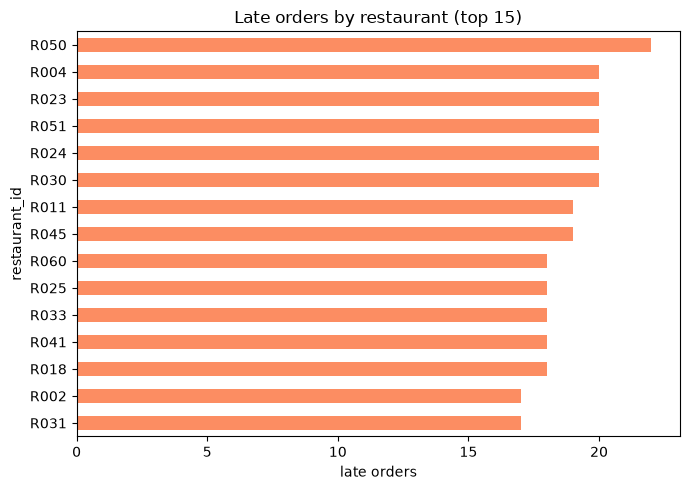

In [14]:
# D. restaurants contributing the most late orders
rest = (valid_outcomes.groupby("restaurant_id")
        .agg(orders=("order_id", "count"), late_orders=("late_flag", "sum"), late_rate=("late_flag", "mean"), median_pickup_slip=("pickup_slip_min", "median"))
        .sort_values("late_orders", ascending=False))
rest["share_of_all_late"] = rest.late_orders / rest.late_orders.sum()
print("D. top restaurants by late orders")
display(rest.head(10).round(2))
print(f"top 10 of {len(rest)} restaurants = {rest.share_of_all_late.head(10).sum():.0%} of late orders")
print("correlation of restaurant late rate with its median pickup slip:", round(rest.late_rate.corr(rest.median_pickup_slip), 2))

rest.head(15).sort_values("late_orders").plot.barh(y="late_orders", legend=False, figsize=(7, 5), color="#fc8d62")
plt.title("Late orders by restaurant (top 15)")
plt.xlabel("late orders")
plt.tight_layout()
plt.show()

In [15]:
# E. support + intervention + still late
e = om[om.support_opened & om.intervention_count.gt(0) & om.late_flag.eq(1)]
print(f"E. {len(e)} journeys had support + an intervention and were still late")
display(e.intervention_types.value_counts())
display(e.sort_values("delay_min", ascending=False)[["order_id", "intervention_types", "pre_delivery_interventions", "pickup_slip_min", "delay_min"]].head(8))
print(f"of these, the only intervention was a credit or came after delivery: {(e.pre_delivery_interventions == 0).sum()}")

E. 67 journeys had support + an intervention and were still late


intervention_types
DRIVER_REASSIGNMENT    26
CUSTOMER_CREDIT        15
PRIORITY_DISPATCH      14
RESTAURANT_CONTACT     12
Name: count, dtype: int64

,order_id,intervention_types,pre_delivery_interventions,pickup_slip_min,delay_min
100,O00101,CUSTOMER_CREDIT,0,8.1,85.51
197,O00198,RESTAURANT_CONTACT,1,38.0,35.23
496,O00497,PRIORITY_DISPATCH,1,34.9,31.78
612,O00613,PRIORITY_DISPATCH,1,32.2,27.18
7,O00008,CUSTOMER_CREDIT,0,31.0,26.86
301,O00302,PRIORITY_DISPATCH,1,32.2,26.32
543,O00544,DRIVER_REASSIGNMENT,1,27.5,24.92
861,O00862,DRIVER_REASSIGNMENT,1,32.5,24.10


of these, the only intervention was a credit or came after delivery: 15


Challenge 5 answers (did all five):

A. Orders with support have way higher delay: ~88% late vs ~49%, median ~12 min late vs about on time. Tells the business: support contact is a strong lateness signal. Doesn't prove: that support causes delay. It's the other way round, SUPPORT_OPENED mostly happens after the promised time has already passed.

B. With vs without an operational intervention before delivery, late rate is basically the same (~55% vs ~57%). Looks like interventions do nothing, but that's selection: they go to orders that are already in trouble (higher pickup slip). So I compared orders that were equally far behind at pickup: still no difference in any band (e.g. 95% late either way at 10 to 20 min behind). So there's no sign they help, but they're also triggered by different things at different times, so it's not a fair test either. Tells the business: you can't judge interventions from a raw with/without split. Doesn't prove: that they work or that they don't. You'd need a proper test (randomly hold back an intervention on some at-risk orders).

C. Priority dispatch has the lowest late rate (~51%), then restaurant contact (~53%) and driver reassignment (~58%). Same order when you only look at orders already 5+ min behind at pickup (80%, 83%, 86%). Customer credit is highest (~67%), but most credits happen after delivery, so it's a response to lateness, not a fix. It doesn't belong in the comparison. Tells the business: priority dispatch is the one to test first. Doesn't prove: it's the best one. The gaps are small, the groups are 50 to 90 orders, and each type gets triggered for different reasons.

D. No single restaurant is the problem. The top 10 of 60 make up ~23% of late orders, and restaurants with higher pickup slip have higher late rates (correlation ~0.7). Tells the business: work on pickup reliability across the board, and use the top of the list for restaurant conversations. Doesn't prove: the restaurant is at fault, since pickup slip mixes kitchen time with driver arrival.

E. 67 journeys had support + an intervention and were still late. For 15 of them the only "intervention" was a credit, so nothing was done to actually speed up the order. The rest mostly had pickups 25 to 38 min behind plan, too far gone for a nudge to save. (Top of the list, O00101, is one of the broken-ETA orders from Class 5, its 85 min "delay" isn't real.) Tells the business: these are the worst experiences, and they're mostly orders where help came too late or not at all. Doesn't prove: the interventions failed, some of these would probably have been even later without them.

# Challenge 6: Connect the model to the KPI

Create a one-page project view:

`PROJECT KPI → OUTCOME METRIC → WORKFLOW/DRIVER METRICS → INTERVENTIONS → DATA SOURCES/EVENTS`

Answer:
1. Which metrics are directly controllable by operations?
2. Which are outcomes?
3. Which missing event limits the model most?
4. What would you instrument next?

Final deliverable:
- core entities,
- key events,
- relationships,
- 3-5 metrics,
- KPI linkage,
- one modelling limitation.

In [16]:
# timing: how soon after the pickup slips do we act?
pre = it[it.before_delivery & it.intervention_type.ne("CUSTOMER_CREDIT")].merge(dispatch[["order_id", "estimated_pickup_at"]], on="order_id")
pre["min_after_planned_pickup"] = (pre.intervention_at - pre.estimated_pickup_at).dt.total_seconds() / 60
print(f"pre-delivery interventions happen a median {pre.min_after_planned_pickup.median():.0f} min after the planned pickup time")
print(f"at-risk orders (pickup slip > 5 min): {at_risk.sum()} | got a pre-delivery intervention: {(at_risk & pre_iv).sum()}")

pre-delivery interventions happen a median 2 min after the planned pickup time
at-risk orders (pickup slip > 5 min): 977 | got a pre-delivery intervention: 209


### Project view

```
PROJECT KPI        Reduce late delivery rate (~56% today)
      |
OUTCOME METRIC     Late delivery rate: late / delivered with known outcome
      |
DRIVER METRICS     Pickup on-plan rate, median pickup slip           <- ~99% of late minutes
                   Late-order support contact rate                    <- how much of it customers feel
      |
INTERVENTIONS      Priority dispatch, restaurant contact, driver reassignment (before delivery)
                   Customer credit (after, recovery only)
                   At-risk intervention coverage                      <- are we acting on the orders that need it
      |
DATA / EVENTS      orders (promise, outcome), dispatch (planned pickup, reassignment),
                   driver app (pickup, delivery), app actions + tickets (interactions),
                   order_interventions (actions), outcomes
```

1. Directly controllable by ops: at-risk intervention coverage and timing (who gets helped and how fast), and partly pickup on-plan rate (driver dispatch timing, restaurant nudges, and fixing the flat 18 min pickup plan).
2. Outcomes: late delivery rate, and the support contact rate on late orders (that's a customer reaction, you can't control it directly).
3. The missing event that limits the model most: food ready at the restaurant, together with driver arrived at the restaurant. The delay builds up between order and pickup, and without these two we can't tell if it's the kitchen or the driver, which decides who fixes it and which intervention to use (restaurant contact vs reassignment).
4. What I'd instrument next: `food_ready_at` from the restaurant (a tap in the restaurant app, stored as an event, not an overwritten status), `driver_arrived_at_restaurant` via geofence, one system of record for interventions (right now `order_events` and `order_interventions` disagree), and a record of when ops noticed an order was at risk so we can see how long it takes to react.

Final deliverable:
- Core entities: customer, order, restaurant, driver
- Key events: created, assigned, reassigned, picked up, delivered, restaurant status, customer interactions, interventions
- Relationships: customer 1 to many orders, and each order 1 to many events, interactions and interventions, plus exactly one outcome
- Metrics: late delivery rate, pickup on-plan rate, median pickup slip, late-order support contact rate, at-risk intervention coverage
- KPI linkage: pickup slip drives lateness, interventions are supposed to catch slipping orders early, and support contact tells us how much of it customers notice
- One limitation: interventions aren't randomly assigned, they go to orders already in trouble, so the model can show where they happen but can't tell us whether they work. That needs a holdout test.

# Final reflection

A strong solution does not produce the largest schema.

It produces the **smallest useful model that explains the workflow and supports the project KPI**.